# LAB | BMI Survey


## Part 1: Descriptive Analysis

## Problem Description

Overweight and obesity, measured by Body Mass Index (BMI), are increasing health concerns in Denmark and globally. This project analyzes BMI data from a Danish survey to provide an overview of BMI distributions and investigate potential factors influencing BMI, such as gender, age, and fast food consumption. The analysis aims to summarize and visualize the data using descriptive statistics and graphical methods.

---

## Instructions

- Complete each section below using Python and appropriate libraries (e.g., pandas, numpy, matplotlib, seaborn).
- Provide code, tables, and figures as needed.
- Write brief explanations for your findings after each analysis step.
- Do **not** include code in your final report; code should be submitted separately as an appendix.
- Ensure all figures and tables are clearly labeled and referenced in your explanations.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [5]:
df = pd.read_csv("https://raw.githubusercontent.com/Dee-M123/lab-eda-bmi/refs/heads/main/your-code/data/bmi1_data.csv", sep=";")

df.head()

,height,weight,gender,urbanity,fastfood
0,180,80,1,5,24.0
1,185,98,1,1,6.0
2,180,80,1,5,6.0
3,168,60,0,4,24.0
4,173,83,1,5,24.0


In [6]:
df.shape

(145, 5)

## Q1. Data Overview

**a) Short Description of the Data**

- List all variables in the dataset.
- Classify each variable as quantitative or categorical.
- State the number of observations.
- Check for missing values.


**Instructions:**  
- Summarize the dataset variables and their types.
- Report the number of observations and any missing values.

---

In [7]:
print(df.info())
print(df.describe())
print(df.isna().mean())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   height    145 non-null    int64  
 1   weight    145 non-null    int64  
 2   gender    145 non-null    int64  
 3   urbanity  145 non-null    int64  
 4   fastfood  145 non-null    float64
dtypes: float64(1), int64(4)
memory usage: 5.8 KB
None
           height      weight      gender    urbanity    fastfood
count  145.000000  145.000000  145.000000  145.000000  145.000000
mean   173.903448   76.737931    0.503448    3.668966   21.037241
std      9.328365   15.208286    0.501721    1.374647   40.321484
min    154.000000   50.000000    0.000000    1.000000    0.000000
25%    166.000000   65.000000    0.000000    3.000000    6.000000
50%    173.000000   75.000000    1.000000    4.000000    6.000000
75%    182.000000   87.000000    1.000000    5.000000   24.000000
max    196.000000  130.000000    1.00000

**Variables in the Dataset**

**height**
- Height of the respondent (in centimeters)

- Quantitative (continuous)

**weight**

- Weight of the respondent (in kilograms)

- Quantitative (continuous)

**gender**

- Respondent’s gender (0 = Female, 1 = Male)

- Categorical (binary)

**urbanity**

- Size of the city/town where the respondent lives (scale 1–5)

- Categorical (ordinal)

**fastfood**

- Number of days per year the respondent eats fast food

- Quantitative (discrete)

In [ ]:
## TODO
### Insert your Answer Here ###

## 2. Calculating BMI

- Compute BMI for each respondent using the formula:

  $$\text{BMI} = \frac{\text{weight (kg)}}{\left[\text{height (m)}\right]^2}$$

- Add BMI as a new column to the dataset.

---


In [11]:
# Convert height from centimeters to meters
df["height_m"] = df["height"] / 100

# Calculate BMI
df["BMI"] = df["weight"] / (df["height_m"] ** 2)

# Preview results
df.head()

,height,weight,gender,urbanity,fastfood,height_m,BMI
0,180,80,1,5,24.0,1.80,24.691358
1,185,98,1,1,6.0,1.85,28.634039
2,180,80,1,5,6.0,1.80,24.691358
3,168,60,0,4,24.0,1.68,21.258503
4,173,83,1,5,24.0,1.73,27.732300


In [9]:
df["BMI"].describe()

,BMI
count,145.000000
mean,25.247948
std,3.832243
min,17.577069
25%,22.589551
50%,24.691358
75%,27.636054
max,39.519741


In [ ]:
## TODO
### Insert your Answer Here ###


## 3. Empirical Distribution of BMI

**b) Density Histogram of BMI Scores**

- Plot a density histogram of BMI.
- Describe the distribution: symmetry, skewness, possible negative values, and variation.

**Instructions:**  
- Comment on the shape and spread of the BMI distribution.

---


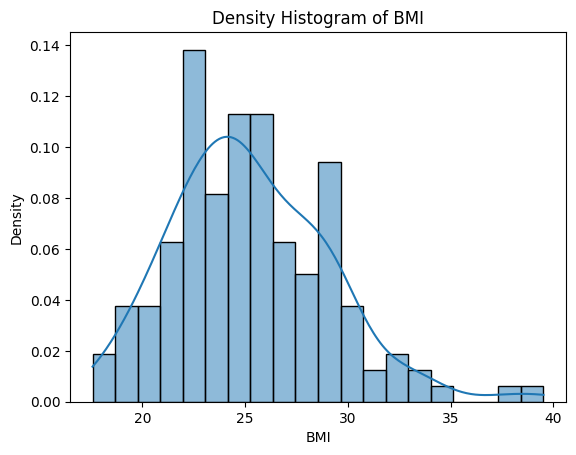

In [12]:

plt.figure()
sns.histplot(df["BMI"], bins=20, kde=True, stat="density")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.title("Density Histogram of BMI")
plt.show()

**Shape and Symmetry**

- The distribution is approximately bell-shaped, but slightly right-skewed.

- The right tail extends toward higher BMI values (above 30), indicating some individuals with obesity.

- The peak of the distribution is around 24–26, which is close to the sample mean (25.25).

**Skewness**

- The longer right tail suggests positive skewness.

 - This is consistent with the mean (25.25) being slightly larger than the median (24.69).

- A small number of high BMI values (above 35) pull the average upward.

**Negative Values**

- No negative values are present.

- The minimum BMI is approximately 17.6, which is realistic and within the underweight range.

- Since BMI is calculated from weight and height, negative values are not possible.

**Variation and Spread**

- Most BMI values lie between 22 and 28.

- The distribution shows moderate dispersion, with a standard deviation of 3.83.

- A few observations above 35 indicate the presence of severe obesity cases.


## 4. Gender Subsets

**c) Separate Density Histograms for Women and Men**

- Create subsets for women and men.
- Plot density histograms for each group.
- Compare and describe the distributions.


**Instructions:**  
- Discuss any gender differences in the BMI distributions.

---


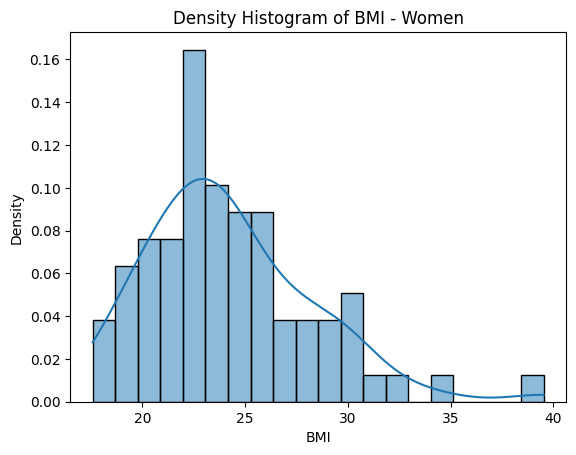

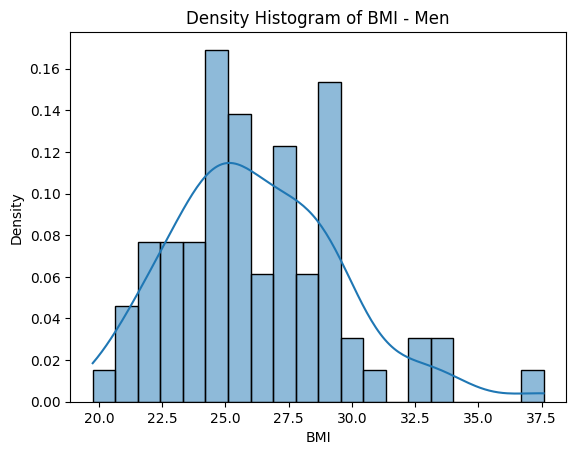

In [13]:

women = df[df["gender"] == 0]
men = df[df["gender"] == 1]

#Women
plt.figure()
sns.histplot(women["BMI"], bins=20, kde=True, stat="density")
plt.title("Density Histogram of BMI - Women")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.show()

#Men
plt.figure()
sns.histplot(men["BMI"], bins=20, kde=True, stat="density")
plt.title("Density Histogram of BMI - Men")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.show()


## 5. Boxplot by Gender

**d) Box Plot of BMI by Gender**

- Create a box plot of BMI scores grouped by gender.
- Describe the distribution, symmetry/skewness, differences, and outliers.

**Instructions:**  
- Interpret the box plot and compare distributions.

---


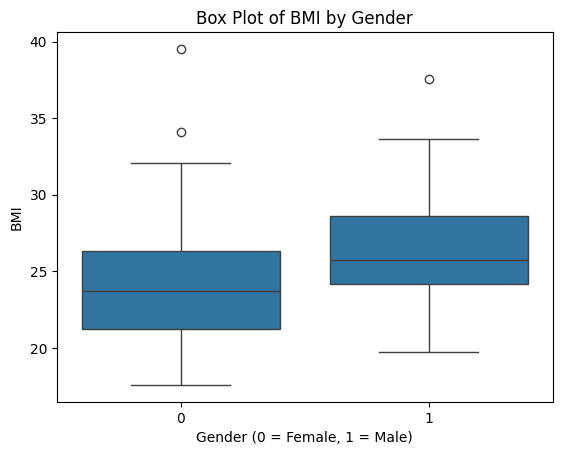

In [14]:
plt.figure()
sns.boxplot(x="gender", y="BMI", data=df)
plt.xlabel("Gender (0 = Female, 1 = Male)")
plt.ylabel("BMI")
plt.title("Box Plot of BMI by Gender")
plt.show()

- The median BMI for men is visibly higher than for women.

- Women have a median BMI around 23–24, while men have a median around 25–26.

- This indicates that men in the sample tend to have higher BMI values on average.

## 6. Summary Statistics

**e) Key Summary Statistics for BMI**

- Calculate and report the following for everyone, women, and men:
  - Number of observations (n)
  - Sample mean (\(\bar{x}\))
  - Sample variance (\(s^2\))
  - Sample standard deviation (\(s\))
  - Lower quartile (Q1)
  - Median (Q2)
  - Upper quartile (Q3)

**Instructions:**  
- Present the summary statistics in a table.
- Discuss what additional insights are provided by the table compared to the box plot.

---


In [15]:
# Summary statistics for everyone
overall_stats = df["BMI"].describe()

# Summary statistics by gender
grouped_stats = df.groupby("gender")["BMI"].describe()

overall_stats, grouped_stats

(count    145.000000
 mean      25.247948
 std        3.832243
 min       17.577069
 25%       22.589551
 50%       24.691358
 75%       27.636054
 max       39.519741
 Name: BMI, dtype: float64,
         count       mean       std        min        25%        50%  \
 gender                                                                
 0        72.0  24.216402  4.051897  17.577069  21.258503  23.689109   
 1        73.0  26.265363  3.326969  19.753086  24.151673  25.725517   
 
               75%        max  
 gender                        
 0       26.291724  39.519741  
 1       28.634039  37.576598  )

## Part 2: Missing Values, Outliers, and Bivariate EDA

## 1. Missing Values

- List the number of missing values for each variable in the dataset.
- Choose and apply appropriate strategies for handling missing values (e.g., removal, imputation).
- Justify your chosen approach.
- Show the number of observations before and after handling missing values.

In [ ]:
#NA

## 2. Outlier Detection and Handling

### a) Identifying Outliers

- Use visual (boxplots, scatterplots) and statistical methods (e.g., IQR rule, z-scores) to detect outliers in BMI, height, and weight.
- List any extreme values found and discuss whether they are plausible or likely errors.



In [ ]:
## TODO
### Insert your Answer Here ###


### b) Handling Outliers

- Decide how to handle detected outliers (e.g., keep, remove, or correct).
- Justify your approach and show the effect on the dataset.



In [16]:

# Calculate quartiles
Q1_bmi = df["BMI"].quantile(0.25)
Q3_bmi = df["BMI"].quantile(0.75)

# Calculate IQR
IQR_bmi = Q3_bmi - Q1_bmi

# Define bounds
lower_bmi = Q1_bmi - 1.5 * IQR_bmi
upper_bmi = Q3_bmi + 1.5 * IQR_bmi

# Identify outliers
bmi_outliers = df[(df["BMI"] < lower_bmi) | (df["BMI"] > upper_bmi)]

bmi_outliers

,height,weight,gender,urbanity,fastfood,height_m,BMI
73,186,130,1,4,78.2,1.86,37.576598
144,163,105,0,3,0.0,1.63,39.519741


## 3. Bivariate Exploratory Data Analysis (EDA)

### a) BMI and Fast Food Consumption

- Create a scatter plot of BMI vs. fast food consumption.
- Calculate and interpret the correlation coefficient.
- Comment on any patterns or associations observed.

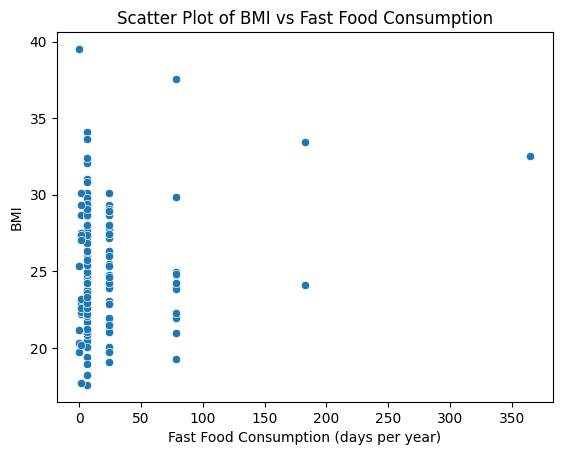

In [17]:
plt.figure()
sns.scatterplot(x="fastfood", y="BMI", data=df)
plt.xlabel("Fast Food Consumption (days per year)")
plt.ylabel("BMI")
plt.title("Scatter Plot of BMI vs Fast Food Consumption")
plt.show()

In [18]:
correlation = df["BMI"].corr(df["fastfood"])
correlation

np.float64(0.1531577674036607)

### b) BMI by Gender

- Use boxplots or violin plots to compare BMI distributions between genders.
- Test for significant differences (e.g., t-test or Mann-Whitney U test).

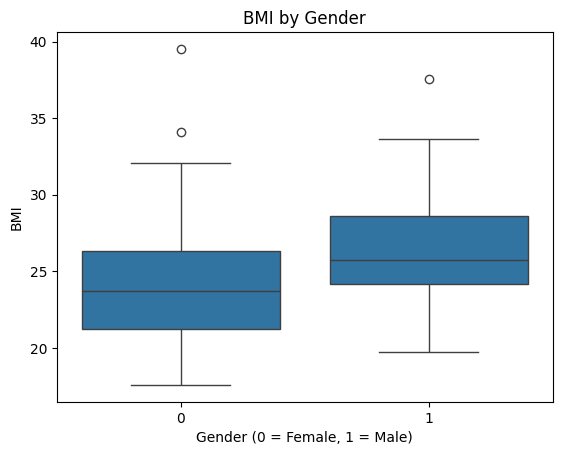

In [19]:
plt.figure()
sns.boxplot(x="gender", y="BMI", data=df)
plt.xlabel("Gender (0 = Female, 1 = Male)")
plt.ylabel("BMI")
plt.title("BMI by Gender")
plt.show()

In [20]:
from scipy.stats import ttest_ind

women = df[df["gender"] == 0]["BMI"]
men = df[df["gender"] == 1]["BMI"]

t_stat, p_value = ttest_ind(women, men)

t_stat, p_value

(np.float64(-3.329873239175403), np.float64(0.0011053964298408038))

### c) BMI by Urbanity

- Visualize BMI across different urbanity categories using boxplots or bar plots.
- Discuss any differences or trends.

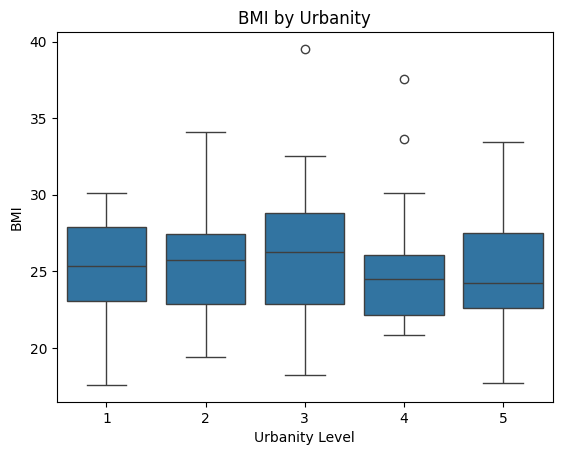

In [21]:
plt.figure()
sns.boxplot(x="urbanity", y="BMI", data=df)
plt.xlabel("Urbanity Level")
plt.ylabel("BMI")
plt.title("BMI by Urbanity")
plt.show()

### d) Additional Bivariate Relationships

- Explore other pairs of variables as relevant (e.g., weight vs. height, fast food vs. gender).
- Use appropriate plots and statistics.

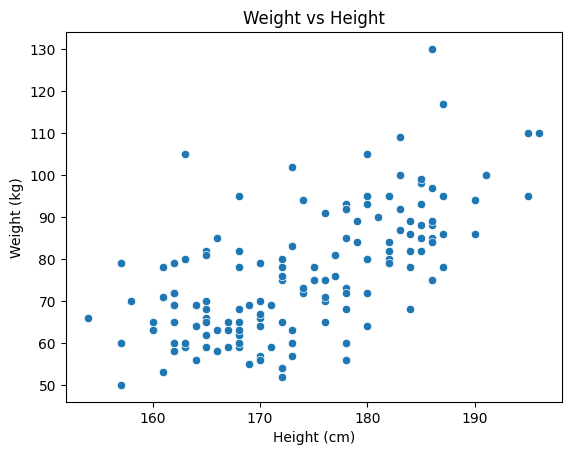

In [22]:
plt.figure()
sns.scatterplot(x="height", y="weight", data=df)
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Weight vs Height")
plt.show()

In [23]:
df["height"].corr(df["weight"])

np.float64(0.6554552330359055)

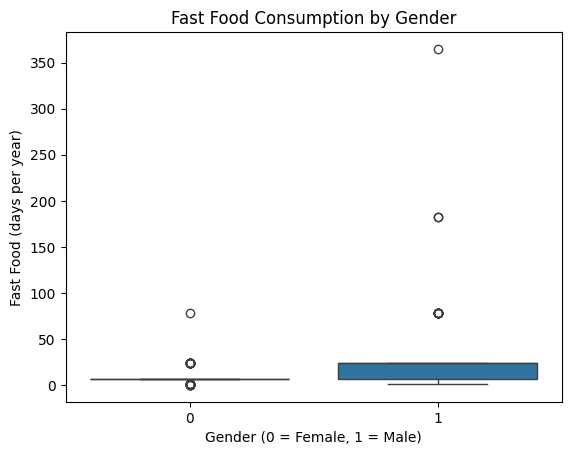

In [24]:
plt.figure()
sns.boxplot(x="gender", y="fastfood", data=df)
plt.xlabel("Gender (0 = Female, 1 = Male)")
plt.ylabel("Fast Food (days per year)")
plt.title("Fast Food Consumption by Gender")
plt.show()

## 4. Summary

- Summarize the key findings from your missing value analysis, outlier handling, and bivariate EDA.
- Discuss how these steps improve the quality and reliability of your subsequent analyses.

The dataset contained no missing values, so no observations had to be removed or imputed. Outlier analysis identified a few high BMI values, but they were biologically plausible and therefore retained. Bivariate EDA showed a weak relationship between BMI and fast food consumption, a significant gender difference in BMI, and no strong trend by urbanity. These steps improve reliability by ensuring data quality, validating assumptions, and identifying meaningful relationships before further analysis.

In [ ]:
## TODO
### Insert your Answer Here ###

Happy Coding .... ;)